E-commerce Customer Spending Prediction using Polynomial Regression

Project Overview

This project uses Machine Learning to predict the yearly spending of e-commerce customers based on their online activity.

Dataset

Ecommerce Customers Dataset (500 customer records).

Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

Algorithm

Polynomial Regression (Degree 2)

Input Features

- Average Session Length
- Time on App
- Time on Website
- Length of Membership

Target Variable

Yearly Amount Spent

Evaluation Metrics

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- R² Score

Visualizations

- Actual vs Predicted Plot
- Correlation Heatmap
- Residual Plot

Expected Outcome

Predict estimated yearly customer spending using customer activity data.

In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
url = "https://raw.githubusercontent.com/sayande01/Kaggle_Notebooks/main/Ecommerce%20Customers.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (500, 8)


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("\nDataset Shape After Cleaning:", df.shape)

df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB

Missing Values:
Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64

Duplicate Rows: 0

Dataset Shape After Cleaning: (500, 8)


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


In [ ]:
X = df[[
    "Avg. Session Length",
    "Time on App",
    "Time on Website",
    "Length of Membership"
]]

y = df["Yearly Amount Spent"]

print("Features selected successfully!")
print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

X.head()

Features selected successfully!
Input Features Shape: (500, 4)
Target Shape: (500,)


,Avg. Session Length,Time on App,Time on Website,Length of Membership
0,34.497268,12.655651,39.577668,4.082621
1,31.926272,11.109461,37.268959,2.664034
2,33.000915,11.330278,37.110597,4.104543
3,34.305557,13.717514,36.721283,3.120179
4,33.330673,12.795189,37.536653,4.446308


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Dataset split successfully!")
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Dataset split successfully!
Training Data: (400, 4)
Testing Data: (100, 4)


In [ ]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Polynomial features created successfully!")
print("Original Features:", X_train.shape)
print("Polynomial Features:", X_train_poly.shape)

Polynomial features created successfully!
Original Features: (400, 4)
Polynomial Features: (400, 15)


In [ ]:
model = LinearRegression()

model.fit(X_train_poly, y_train)

print("Polynomial Regression Model trained successfully!")

Polynomial Regression Model trained successfully!


In [ ]:
y_pred = model.predict(X_test_poly)

print("Predictions completed successfully!")

results = pd.DataFrame({
    "Actual Amount": y_test.values,
    "Predicted Amount": y_pred
})

results.head(10)

Predictions completed successfully!


,Actual Amount,Predicted Amount
0,401.033135,408.236531
1,534.777188,542.424624
2,418.602742,430.014040
3,503.978379,501.431973
4,410.069611,410.113565
5,557.608262,568.938851
6,538.941975,529.021534
7,514.336558,505.801079
8,408.620188,408.452342
9,475.015407,474.354894


In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")

Model Evaluation Results
------------------------
Mean Absolute Error: 8.84
Mean Squared Error: 116.07
R2 Score: 0.9766
R2 Percentage: 97.66 %


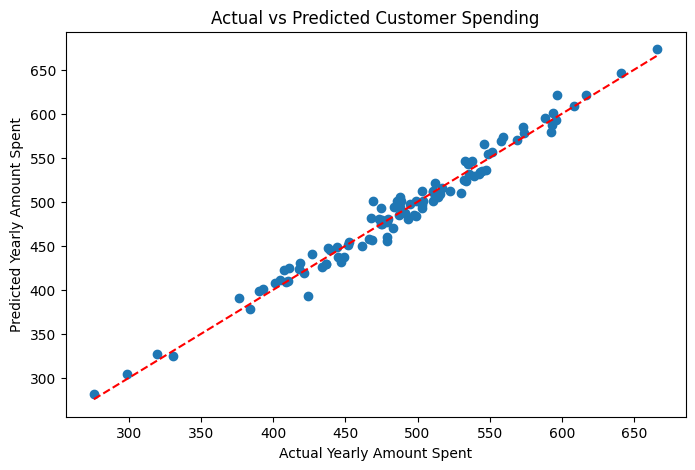

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Yearly Amount Spent")
plt.ylabel("Predicted Yearly Amount Spent")
plt.title("Actual vs Predicted Customer Spending")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.show()

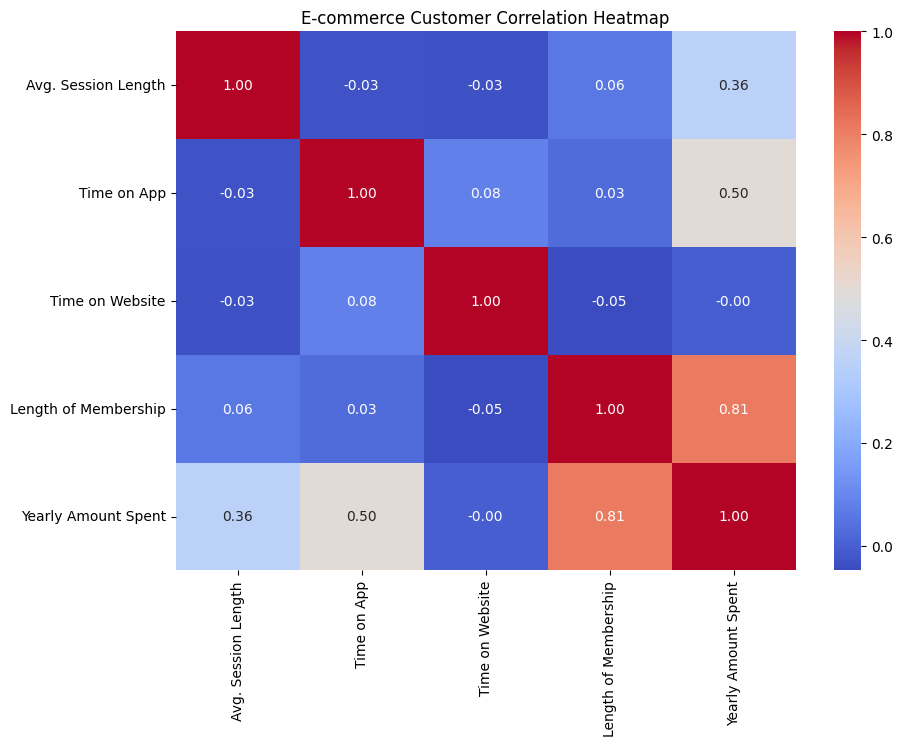

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("E-commerce Customer Correlation Heatmap")
plt.show()

In [ ]:
new_customer = pd.DataFrame({
    "Avg. Session Length": [34.5],
    "Time on App": [12.5],
    "Time on Website": [39.0],
    "Length of Membership": [4.0]
})

new_customer_poly = poly.transform(new_customer)

predicted_amount = model.predict(new_customer_poly)

print(
    "Predicted Yearly Amount Spent:",
    round(predicted_amount[0], 2)
)

Predicted Yearly Amount Spent: 583.09


In [ ]:
import joblib

joblib.dump(
    {"model": model, "poly": poly},
    "ecommerce_polynomial_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("ecommerce_polynomial_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
feature_names = poly.get_feature_names_out(X.columns)

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model.coef_
})

print("Polynomial Regression Coefficients:")
print(coefficients.to_string(index=False))

Polynomial Regression Coefficients:
                                 Feature  Coefficient
                                       1     0.000000
                     Avg. Session Length    46.425085
                             Time on App    46.498023
                         Time on Website   -28.468319
                    Length of Membership    84.068436
                   Avg. Session Length^2    -0.503522
         Avg. Session Length Time on App     0.372048
     Avg. Session Length Time on Website     0.259651
Avg. Session Length Length of Membership    -0.489319
                           Time on App^2     0.484103
             Time on App Time on Website    -0.871404
        Time on App Length of Membership     0.159599
                       Time on Website^2     0.423984
    Time on Website Length of Membership    -0.218353
                  Length of Membership^2     0.027597


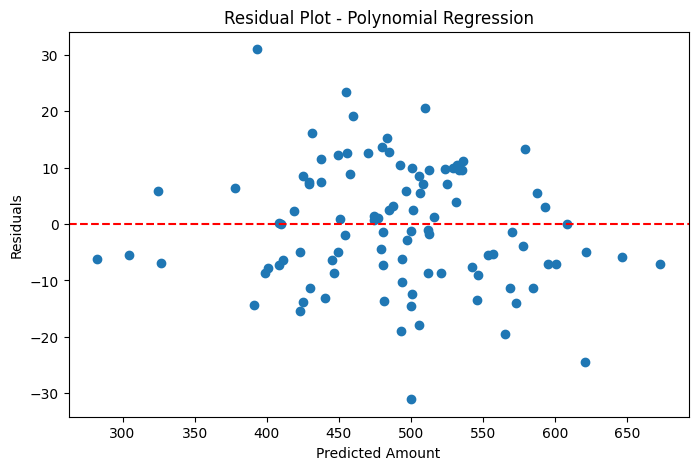

In [ ]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Amount")
plt.ylabel("Residuals")
plt.title("Residual Plot - Polynomial Regression")

plt.show()

Conclusion

In this project, we developed an E-commerce Customer Spending Prediction model using Polynomial Regression.

We used the Ecommerce Customers dataset and selected Average Session Length, Time on App, Time on Website, and Length of Membership as input features.

PolynomialFeatures with degree 2 was used to generate polynomial features. A Linear Regression model was trained using these features.

The model was evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), and R² Score.

We also created visualizations such as the Actual vs Predicted Plot, Correlation Heatmap, and Residual Plot.

Finally, we tested the model with new customer data.

This project demonstrates how Polynomial Regression can be applied to estimate yearly customer spending based on customer activity.

Note: Predictions are estimates based on this dataset and should not be treated as guaranteed customer spending.